# 06 · Experiments against the frozen reference B0

| id | change vs B0 | motivation |
|---|---|---|
| X1 | one model per language, each with its own feature/regularisation search | EN and DE differ in domains, length behaviour, casing and compounding (`01_eda`) |
| X2 | two-stage: stage-1 domain classifier → per-domain expert | class priors and AI style differ by domain |
| X2g | X2 with routing by the given `domain` column | the test set has the domain column; X2 vs X2g isolates the cost of stage-1 routing errors |
| X5 | two-stage label cascade: ai vs not-ai, then a human-vs-fusion specialist | ai is easy, human vs fusion is the hard pair; a specialist spends all its capacity on that pair |
| X6 | character n-grams instead of word n-grams | a weaker but different model, added for ensemble diversity |
| X8 | masked word n-grams: only frequent words and punctuation are kept, other words become `*` of the same length | style and syntax with almost no topic signal, a member that should hold across domains |
| S1 | stacker over B0, X6 and X8 trained on 5-fold out-of-fold scores of all 245k train texts (+ domain, text stats) | the validation stacker X4 only has 27k rows (5k German); S1 learns the combination on 9× more rows |
| X7 | two-stage sentence model: sentence labels original / rewritten / ai from train fusion texts and their human source, then per-text summaries of the sentence scores | a fusion text is a human text with some sentences rewritten (`01_eda`: shared 3-grams with the source by position) |
| X3 | LM likelihood + segment features → gradient boosting | model-based signal independent of n-grams; segment spread aimed at fusion |
| E1 | fine-tuned multilingual encoder (from `04_encoder`) | required encoder comparison |

Every run writes `artifacts/runs/<id>.json` (config, compute, runtime, status, error if it failed) and predictions to `artifacts/preds/`. The log at the end is rebuilt from these files.

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

from hw3.config import ROOT, art, load_config

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)
FIG = ROOT / "images"

from hw3 import ensemble, lm, sentences, tfidf
from hw3.runs import compare, experiment_log, has_preds, report

/home/luka/study/ai_course/ai-text-detection-hw3-ucu-ai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## X1 · language-specific models

In [2]:
grids = tfidf.run_lang_tuned(load_config("lang_tuned"))
pd.concat(grids, names=["lang"])[["features", "model", "macro_f1", "f1_human", "f1_ai", "f1_fusion"]]

features                                              model  macro_f1  f1_human     f1_ai  f1_fusion
lang                                                                                                                             
en-EN 0                [word12_cased]  {'name': 'linear_svc', 'C': 3.0, 'class_weight...  0.833736  0.771749  0.975024   0.754436
      1                [word12_cased]  {'name': 'linear_svc', 'C': 1.0, 'class_weight...  0.832901  0.774521  0.975626   0.748557
      2                      [word12]  {'name': 'linear_svc', 'C': 1.0, 'class_weight...  0.828617  0.769628  0.974317   0.741908
      3                      [word12]  {'name': 'linear_svc', 'C': 3.0, 'class_weight...  0.828164  0.765523  0.974006   0.744962
      4                [word12_cased]  {'name': 'linear_svc', 'C': 0.3, 'class_weight...  0.825551  0.772651  0.973943   0.730057
      5                      [word12]  {'name': 'linear_svc', 'C': 0.3, 'class_weight...  0.822641  0.768112  0.973670   0.726142
de-DE 0  [word12_cased, char35_cased]  {'name': 'linear_svc', 'C': 1.0, 'class_weight...  0.910685  0.875120  0.986771   0.870165
      1  [word12_cased, char35_cased]  {'name': 'linear_svc', 'C': 3.0, 'class_weight...  0.909865  0.873868  0.984796   0.870930
      2                      [word12]  {'name': 'linear_svc', 'C': 3.0, 'class_weight...  0.906103  0.871383  0.980718   0.866208
      3                [word12_cased]  {'name': 'linear_svc', 'C': 3.0, 'class_weight...  0.904827  0.867864  0.981427   0.865189
      4                      [word12]  {'name': 'linear_svc', 'C': 1.0, 'class_weight...  0.904474  0.869538  0.982902   0.860984
      5  [word12_cased, char35_cased]  {'name': 'linear_svc', 'C': 0.3, 'class_weight...  0.902617  0.864306  0.987540   0.856005
      6                [word12_cased]  {'name': 'linear_svc', 'C': 1.0, 'class_weight...  0.901150  0.863864  0.983142   0.856443
      7                [word12_cased]  {'name': 'linear_svc', 'C': 0.3, 'class_weight...  0.895289  0.859698  0.981960   0.844209
      8                      [word12]  {'name': 'linear_svc', 'C': 0.3, 'class_weight...  0.891926  0.854501  0.982687   0.838589

In [3]:
compare(["B0", "X1"], by=["lang"])

,B0,X1
all,0.8657,0.8693
de-DE,0.9068,0.9095
en-EN,0.8544,0.8584


## X2 · two-stage domain routing

In [4]:
routes = tfidf.run_two_stage(load_config("two_stage"))
meta = json.loads(art("runs", "X2.json").read_text())
meta["domain_accuracy_val"], meta["experts"]

(0.988433575677462,
 ['*',
  'de-DE|bundestag',
  'en-EN|arxiv_papers',
  'en-EN|blog_authorship_corpus',
  'en-EN|cnn_news',
  'en-EN|euro_court_cases',
  'en-EN|gutenberg',
  'en-EN|house_of_commons',
  'en-EN|student_essays'])

In [5]:
pd.crosstab(np.asarray(routes["val"]["given"]), np.asarray(routes["val"]["predicted"]), rownames=["given"], colnames=["predicted"])

predicted,de-DE|bundestag,de-DE|gutenberg,en-EN|arxiv_papers,en-EN|blog_authorship_corpus,en-EN|cnn_news,en-EN|euro_court_cases,en-EN|gutenberg,en-EN|house_of_commons,en-EN|student_essays
given,,,,,,,,,
de-DE|bundestag,5212,0,0,5,2,0,2,14,0
de-DE|gutenberg,9,21,0,0,0,0,9,0,0
en-EN|arxiv_papers,2,0,1418,6,3,0,0,0,0
en-EN|blog_authorship_corpus,3,0,0,3971,59,0,10,0,12
en-EN|cnn_news,2,0,2,28,4374,0,10,6,7
en-EN|euro_court_cases,3,0,0,4,9,2740,0,2,0
en-EN|gutenberg,0,0,6,21,9,1,648,4,3
en-EN|house_of_commons,0,0,0,23,7,0,0,3155,1
en-EN|student_essays,2,0,0,27,1,0,1,0,5380


In [6]:
compare(["B0", "X2", "X2g"])

B0      X2     X2g
all   all                     0.8657  0.8665  0.8665
de-DE bundestag               0.9072  0.9051  0.9051
      gutenberg               0.4953  0.4953  0.4953
en-EN arxiv_papers            0.8494  0.8786  0.8786
      blog_authorship_corpus  0.7376  0.7380  0.7380
      cnn_news                0.8272  0.8252  0.8259
      euro_court_cases        0.8991  0.9039  0.9039
      gutenberg               0.7373  0.7205  0.6912
      house_of_commons        0.8725  0.8872  0.8870
      student_essays          0.9097  0.9056  0.9061

## X5 · two-stage label cascade

Stage 1 separates ai from not-ai; stage 2 is trained only on human and fusion texts. Both use B0's features and model. The saved scores reproduce the cascade decision under argmax.

In [2]:
tfidf.run_cascade(load_config("cascade"))
compare(["B0", "X5"])

B0      X5
all   all                     0.8657  0.8833
de-DE bundestag               0.9072  0.9201
      gutenberg               0.4953  0.5000
en-EN arxiv_papers            0.8494  0.9060
      blog_authorship_corpus  0.7376  0.7563
      cnn_news                0.8272  0.8683
      euro_court_cases        0.8991  0.9179
      gutenberg               0.7373  0.8429
      house_of_commons        0.8725  0.8947
      student_essays          0.9097  0.9159

## X6 · character n-grams (diverse member)

Weaker on its own than the word models, but it splits text differently; its value is measured in the ensemble (`07`).

In [3]:
grid = tfidf.run_baseline(load_config("char"))
display(grid[["model", "macro_f1", "f1_human", "f1_ai", "f1_fusion"]])
compare(["B0", "X6"])

,model,macro_f1,f1_human,f1_ai,f1_fusion
0,"{'name': 'linear_svc', 'C': 0.3, 'class_weight...",0.763111,0.676485,0.965340,0.647510
1,"{'name': 'linear_svc', 'C': 1.0, 'class_weight...",0.763026,0.660560,0.967440,0.661080
2,"{'name': 'linear_svc', 'C': 0.1, 'class_weight...",0.753060,0.683874,0.957984,0.617324


B0      X6
all   all                     0.8657  0.8080
de-DE bundestag               0.9072  0.7714
      gutenberg               0.4953  0.5000
en-EN arxiv_papers            0.8494  0.6167
      blog_authorship_corpus  0.7376  0.7604
      cnn_news                0.8272  0.8495
      euro_court_cases        0.8991  0.7751
      gutenberg               0.7373  0.6353
      house_of_commons        0.8725  0.8284
      student_essays          0.9097  0.8403

## X7 · sentence-level labels from fusion/source pairs

For train fusion texts whose human source is among their TF-IDF neighbours, each sentence is labelled *rewritten* when under 30% of its word 3-grams occur in the source and *original* when at least 99% do; sentences of human texts are *original* and of ai texts *ai*. Stage 1 is a sentence classifier (B0 features); stage 2 is gradient boosting over per-text summaries of the sentence scores (mean/max/min/std, share of flagged sentences, rewritten score by third of the text). The two stages are fitted on disjoint train groups. `sentence_f1_val` is the sentence-level F1 on validation pairs.

In [3]:
sentences.run_sentences(load_config("sentences"))
meta = json.loads(art("runs", "X7.json").read_text())
display(meta["sentences_fit"], meta["sentence_f1_val"])
compare(["B0", "X5", "X7"])

{'ai': 1125026, 'original': 1065179, 'rewritten': 83029}

{'original': 0.9168, 'rewritten': 0.3048, 'ai': 0.8941}

B0      X5      X7
all   all                     0.8657  0.8833  0.9077
de-DE bundestag               0.9072  0.9201  0.9322
      gutenberg               0.4953  0.5000  0.4804
en-EN arxiv_papers            0.8494  0.9060  0.9102
      blog_authorship_corpus  0.7376  0.7563  0.7732
      cnn_news                0.8272  0.8683  0.9120
      euro_court_cases        0.8991  0.9179  0.9447
      gutenberg               0.7373  0.8429  0.9389
      house_of_commons        0.8725  0.8947  0.9424
      student_essays          0.9097  0.9159  0.9326

## X8 · masked word n-grams (text distortion)

The most frequent words of the fitted training texts (300 or 1,000, one list for both languages) and punctuation are kept; every other word is replaced by `*` repeated to its length. Word 1–3-grams of the result go into the usual TF-IDF + linear SVM search. Like X6, its value is mainly measured in the ensemble.

In [3]:
grid = tfidf.run_baseline(load_config("masked"))
display(grid[["features", "model", "macro_f1", "f1_human", "f1_ai", "f1_fusion"]])
compare(["B0", "X6", "X8"])

,features,model,macro_f1,f1_human,f1_ai,f1_fusion
0,[masked1000],"{'name': 'linear_svc', 'C': 1.0, 'class_weight...",0.829075,0.761326,0.975702,0.750197
1,[masked1000],"{'name': 'linear_svc', 'C': 0.3, 'class_weight...",0.821359,0.758099,0.973295,0.732681
2,[masked300],"{'name': 'linear_svc', 'C': 1.0, 'class_weight...",0.812279,0.737215,0.972445,0.727177
3,[masked300],"{'name': 'linear_svc', 'C': 0.3, 'class_weight...",0.811629,0.744221,0.970285,0.720382
4,[masked1000],"{'name': 'linear_svc', 'C': 0.1, 'class_weight...",0.801473,0.742472,0.966633,0.695313
5,[masked300],"{'name': 'linear_svc', 'C': 0.1, 'class_weight...",0.794658,0.732298,0.965218,0.686459


B0      X6      X8
all   all                     0.8657  0.8080  0.8667
de-DE bundestag               0.9072  0.7714  0.9070
      gutenberg               0.4953  0.5000  0.5000
en-EN arxiv_papers            0.8494  0.6167  0.8887
      blog_authorship_corpus  0.7376  0.7604  0.7462
      cnn_news                0.8272  0.8495  0.8253
      euro_court_cases        0.8991  0.7751  0.8985
      gutenberg               0.7373  0.6353  0.6505
      house_of_commons        0.8725  0.8284  0.8985
      student_essays          0.9097  0.8403  0.8975

## S1 · stacker trained on the train part

Needs B0, X6 and X8 from above. Each of them is refitted 5 times on train folds (groups from `02_split`) to get out-of-fold scores for every train text, cached as `preds/<member>_trainoof.parquet`; a per-language gradient-boosting stacker is fitted on those 245k rows with the given domain and text stats. Its validation score is fully out-of-sample. About 20 min on CPU with a peak of about 17 GB RAM.

In [4]:
ensemble.run_train_stack(load_config("train_stack"))
compare(["B0", "X6", "X8", "S1"])

B0      X6      X8      S1
all   all                     0.8657  0.8080  0.8667  0.9093
de-DE bundestag               0.9072  0.7714  0.9070  0.9288
      gutenberg               0.4953  0.5000  0.5000  0.4953
en-EN arxiv_papers            0.8494  0.6167  0.8887  0.9328
      blog_authorship_corpus  0.7376  0.7604  0.7462  0.8044
      cnn_news                0.8272  0.8495  0.8253  0.9245
      euro_court_cases        0.8991  0.7751  0.8985  0.9317
      gutenberg               0.7373  0.6353  0.6505  0.8622
      house_of_commons        0.8725  0.8284  0.8985  0.9267
      student_essays          0.9097  0.8403  0.8975  0.9285

## X3 · LM likelihood features

Needs `artifacts/features/lm_*.parquet` from `05_lm_features`.

In [5]:
if art("features", "lm_train.parquet").exists():
    lm.run_classifier(load_config("lm_features"))
compare(["B0", "X3"])

B0      X3
all   all                     0.8657  0.6818
de-DE bundestag               0.9072  0.7265
      gutenberg               0.4953  0.5143
en-EN arxiv_papers            0.8494  0.5705
      blog_authorship_corpus  0.7376  0.5662
      cnn_news                0.8272  0.6895
      euro_court_cases        0.8991  0.6080
      gutenberg               0.7373  0.5942
      house_of_commons        0.8725  0.6381
      student_essays          0.9097  0.7236

## E1 · encoder vs baseline

Needs `artifacts/preds/E1_*.parquet` from `04_encoder`.

In [6]:
compare(["B0", "E1"])

B0      E1
all   all                     0.8657  0.9304
de-DE bundestag               0.9072  0.9244
      gutenberg               0.4953  0.6000
en-EN arxiv_papers            0.8494  0.6278
      blog_authorship_corpus  0.7376  0.8772
      cnn_news                0.8272  0.9765
      euro_court_cases        0.8991  0.9005
      gutenberg               0.7373  0.8613
      house_of_commons        0.8725  0.9261
      student_essays          0.9097  0.9604

## Per-class metrics of every model

,precision,recall,f1,support
B0,,,,
human,0.7559,0.8799,0.8132,6672
ai,0.9708,0.9852,0.9779,12196
fusion,0.8783,0.7444,0.8058,8366


,precision,recall,f1,support
X1,,,,
human,0.7570,0.8919,0.8190,6672
ai,0.9724,0.9867,0.9795,12196
fusion,0.8887,0.7432,0.8095,8366


,precision,recall,f1,support
X2,,,,
human,0.7546,0.8909,0.8171,6672
ai,0.9691,0.9871,0.9780,12196
fusion,0.8874,0.7355,0.8043,8366


,precision,recall,f1,support
X2g,,,,
human,0.7547,0.8906,0.8171,6672
ai,0.9684,0.9874,0.9778,12196
fusion,0.8884,0.7355,0.8047,8366


,precision,recall,f1,support
X5,,,,
human,0.7829,0.8754,0.8266,6672
ai,0.9827,0.9924,0.9875,12196
fusion,0.8867,0.7903,0.8357,8366


,precision,recall,f1,support
X6,,,,
human,0.6711,0.8002,0.7300,6672
ai,0.9682,0.9879,0.9779,12196
fusion,0.7965,0.6506,0.7162,8366


... (2 outputs left out)

,precision,recall,f1,support
S1,,,,
human,0.8164,0.9141,0.8625,6672
ai,0.9927,0.9936,0.9932,12196
fusion,0.9189,0.8299,0.8721,8366


,precision,recall,f1,support
X3,,,,
human,0.5563,0.6841,0.6136,6672
ai,0.8894,0.8622,0.8756,12196
fusion,0.6008,0.5176,0.5561,8366


,precision,recall,f1,support
E1,,,,
human,0.9004,0.8756,0.8878,6672
ai,0.9867,0.9983,0.9925,12196
fusion,0.9088,0.9132,0.9110,8366


,precision,recall,f1,support
E2,,,,
human,0.9037,0.8889,0.8963,6672
ai,0.9850,0.9988,0.9919,12196
fusion,0.9140,0.9074,0.9107,8366


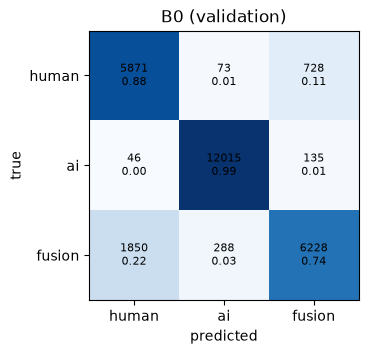

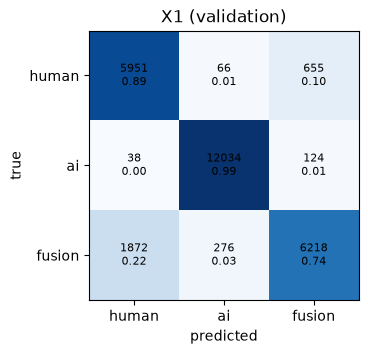

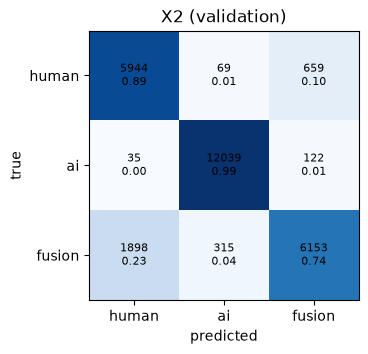

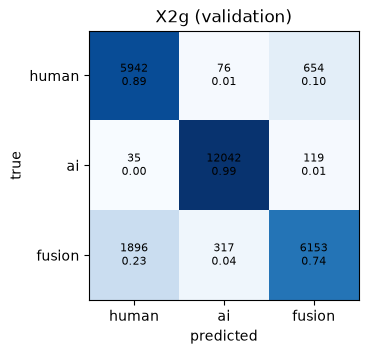

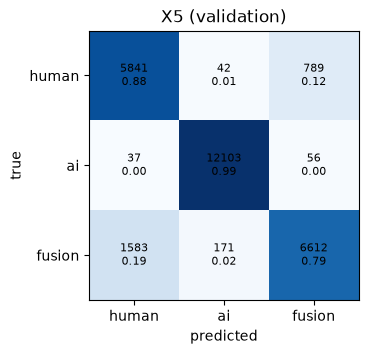

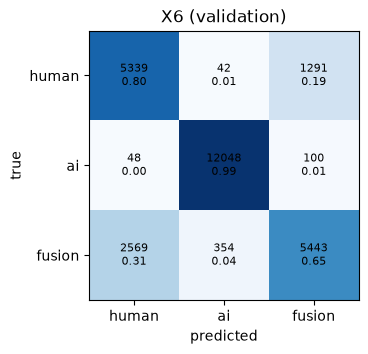

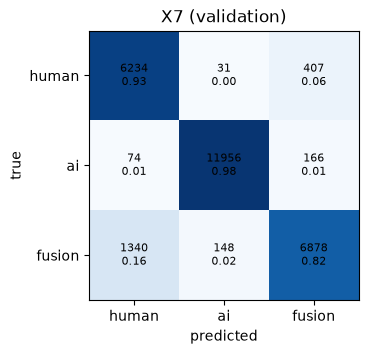

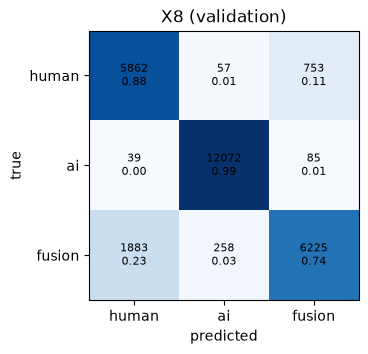

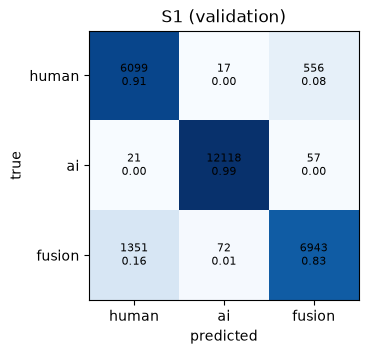

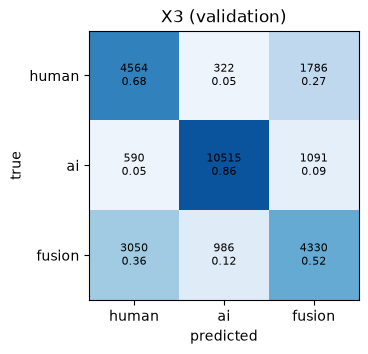

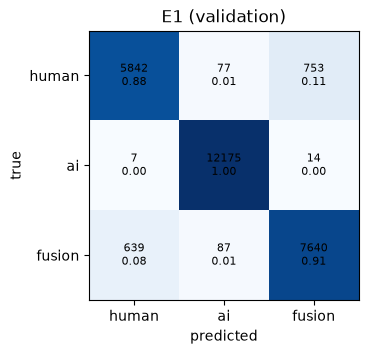

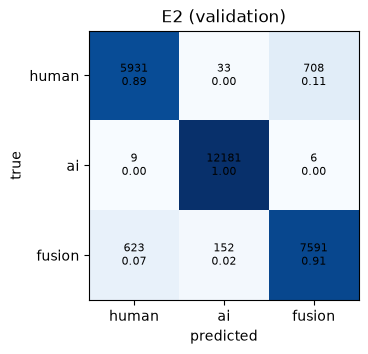

In [7]:
for model_id in ["B0", "X1", "X2", "X2g", "X5", "X6", "X7", "X8", "S1", "X3", "E1", "E2"]:
    if has_preds(model_id, "val"):
        rep = report(model_id)
        rep["figure"].savefig(FIG / f"confusion_{model_id}.png", dpi=150, bbox_inches="tight")
        display(rep["per_class"].rename_axis(model_id))

## Experiment log (`experiments/log.csv`)

In [8]:
experiment_log()

,id,reference,change,status,device,runtime_s,macro_f1,delta_vs_ref,f1_human,f1_ai,f1_fusion,notes
0,B0,NaN,reference model: global word TF-IDF (hashing) ...,ok,cpu,269.5,0.8657,NaN,0.8132,0.9779,0.8058,frozen before any experiment; every experiment...
1,E1,B0,fine-tuned XLM-R base; trains on one random 51...,ok,Tesla T4,8887.7,0.9304,0.0647,0.8878,0.9925,0.9110,max_chunks from EDA token counts: p99 of windo...
2,E2,E1,token-level XLM-R base: every token is tagged ...,ok,Tesla T4,8411.5,0.9329,0.0025,0.8963,0.9919,0.9107,targets lightly rewritten fusion: X4 calls 44%...
3,S1,B0,stacker trained on the train part: 5-fold grou...,ok,cpu,1201.4,0.9093,0.0436,0.8625,0.9932,0.8721,the X4 stacker only has 27k validation rows (5...
4,X1,B0,one model per language with its own feature/re...,ok,cpu,586.4,0.8693,0.0036,0.8190,0.9795,0.8095,motivated by EN/DE differences in EDA: German ...
5,X2,B0,two-stage: stage-1 domain classifier routes ea...,ok,cpu,277.6,0.8665,0.0008,0.8171,0.9780,0.8043,domains have very different class priors and s...
6,X2g,B0,two-stage with routing by the given domain col...,ok,cpu,NaN,0.8665,0.0008,0.8171,0.9778,0.8047,domains have very different class priors and s...
7,X3,B0,open-weight LM likelihood features (observer/p...,ok,cpu,6.9,0.6818,-0.1839,0.6136,0.8756,0.5561,segment spread targets fusion (partly rewritte...
8,X3_features,B0,open-weight LM likelihood features (observer/p...,ok,Tesla T4,8554.9,NaN,NaN,NaN,NaN,NaN,segment spread targets fusion (partly rewritte...
9,X4,B0,two-stage stacked ensemble: stage 1 diverse ba...,ok,cpu,88.9,0.9596,0.0939,0.9357,0.9974,0.9456,stacker is trained and scored with group k-fol...
